# Sesión 1: Aprendizaje No Supervisado de Máquina con el dataset Iris

## ¿Qué es el Aprendizaje No Supervisado?
El aprendizaje no supervisado es una rama del aprendizaje automático que trabaja con datos sin etiquetas para encontrar patrones intrínsecos.

**Objetivos principales:**
1. Descubrir agrupamientos
2. Reducir complejidad
3. Detectar anomalías

In [1]:
# Cargar el dataset Iris
from sklearn.datasets import load_iris
import pandas as pd
import numpy as np

iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
print('Primeras filas del dataset Iris:')
display(X.head())

Primeras filas del dataset Iris:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### 1: Identificación Conceptual de Patrones en Iris
Imagina que no conocemos las especies. ¿Qué patrones podríamos encontrar solo con las características?

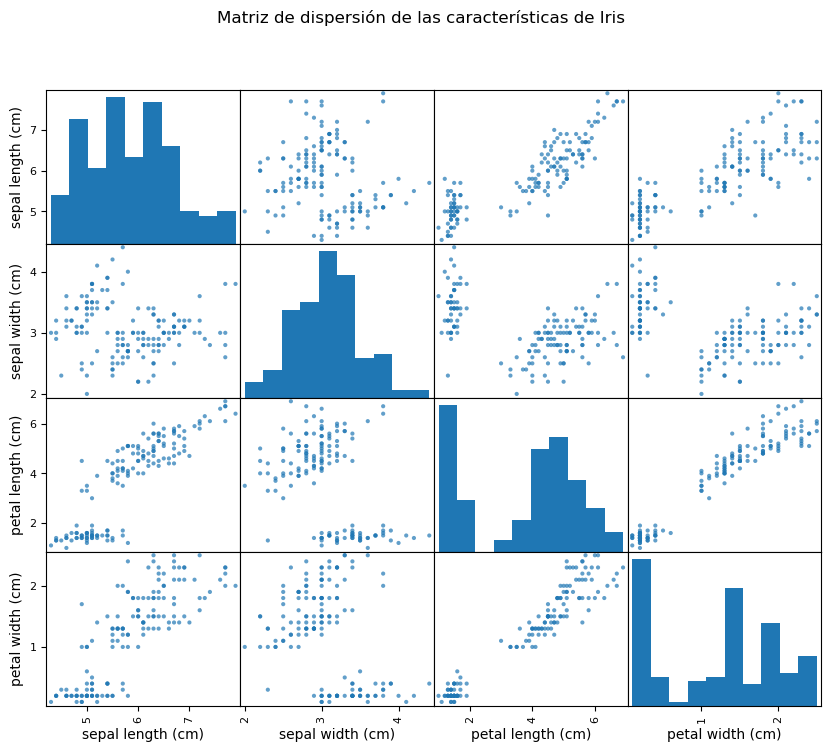

In [2]:
# Visualización rápida de las características
import matplotlib.pyplot as plt
pd.plotting.scatter_matrix(X, figsize=(10, 8), alpha=0.7)
plt.suptitle('Matriz de dispersión de las características de Iris')
plt.show()

## Ventajas y Desventajas del Aprendizaje No Supervisado
**Ventajas:** Descubre patrones desconocidos, no requiere etiquetas, adaptable a varios dominios.
**Desventajas:** Puede ser difícil de interpretar, no siempre útil, difícil de validar.

### 2: Clusterización de Iris (K-Means)
Agrupa las muestras de Iris en 3 clusters y analiza los resultados.

Cantidad de muestras por cluster:
Cluster
0    62
1    50
2    38
Name: count, dtype: int64


c:\Users\adria\miniconda3\envs\myenv\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


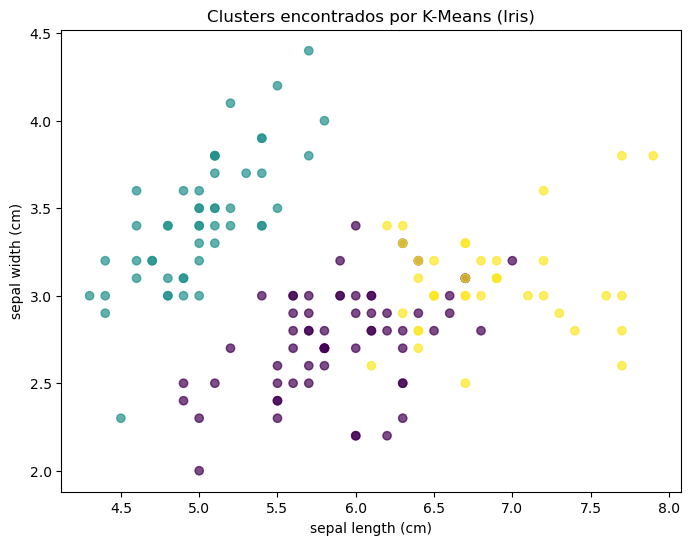

In [3]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X)
X['Cluster'] = clusters
print('Cantidad de muestras por cluster:')
print(X['Cluster'].value_counts())

# Visualización de los clusters en dos dimensiones principales
plt.figure(figsize=(8,6))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=clusters, cmap='viridis', alpha=0.7)
plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title('Clusters encontrados por K-Means (Iris)')
plt.show()

### 3: Reducción de Dimensionalidad (PCA)
Reduce las dimensiones de Iris a 2 componentes principales y visualiza los datos.

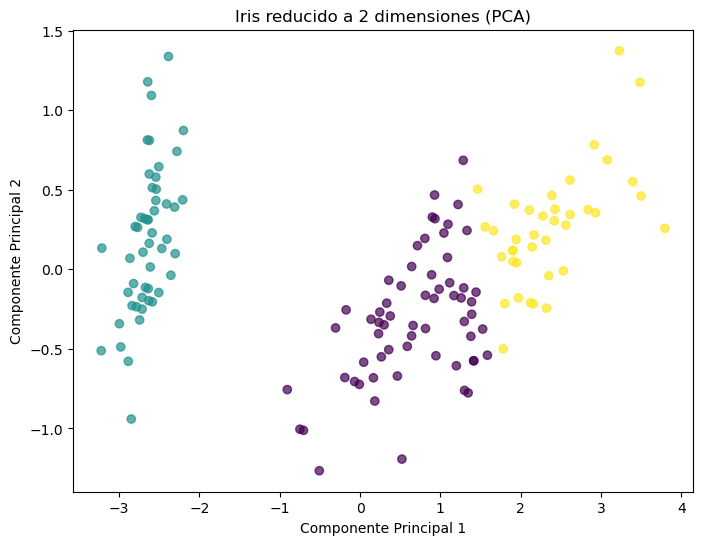

In [4]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X.drop('Cluster', axis=1))
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters, cmap='viridis', alpha=0.7)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.title('Iris reducido a 2 dimensiones (PCA)')
plt.show()

### 4: Detección de Anomalías en Iris
Detecta posibles anomalías usando el método de vecinos más cercanos.

In [5]:
from sklearn.neighbors import LocalOutlierFactor
lof = LocalOutlierFactor(n_neighbors=20)
outlier_pred = lof.fit_predict(X.drop('Cluster', axis=1))
anomalies = X[outlier_pred == -1]
print(f'Se detectaron {len(anomalies)} posibles anomalías en el dataset Iris.')
display(anomalies)

Se detectaron 6 posibles anomalías en el dataset Iris.


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster
15,5.7,4.4,1.5,0.4,1
41,4.5,2.3,1.3,0.3,1
98,5.1,2.5,3.0,1.1,0
117,7.7,3.8,6.7,2.2,2
118,7.7,2.6,6.9,2.3,2
131,7.9,3.8,6.4,2.0,2


## Aplicaciones
El aprendizaje no supervisado permite segmentar, reducir complejidad y detectar anomalías en datos reales como Iris.
